In [2]:
#
# Cell 1: import libraries
#

import numpy as np
import pandas as pd
import pickle
import random

In [6]:
#
# Cell 2: Specify the directory name for loading of data
#

from pathlib import Path

directory_path = Path("D:/ECG/X_zero")

In [88]:
#
# Cell 3:Loading stored raw data, if available. 
#

X = np.load(directory_path/'X_float32.npy', mmap_mode='r')
#Y = pd.read_pickle('Y_data.pkl')
X_mixed=X.copy()

In [53]:
#
# Cell 4: Defines list with values to which randomnly index j is assigned. 
# Index j is needed for the next cell  
#

random_list=[200, 400, 600, 1000]
random_list

[200, 400, 600, 1000]

In [90]:
#
# Cell 5: For-loop for to shorten the length of the ECGs by assigning zero values 
# starting at index value chosen randomnly from random list 
#

for i in range(X_mixed.shape[0]):
    j = np.random.choice(random_list)
    X_mixed[i,j:,:]=0

In [100]:
#
# Cell 5a: only for analysis of the froduced shortenend ECGs 
#

X_mixed[15:20]

array([[[ 0.007, -0.038, -0.045, ...,  0.105, -0.046, -0.065],
        [ 0.004, -0.06 , -0.064, ...,  0.097, -0.052, -0.072],
        [ 0.017, -0.065, -0.082, ...,  0.082, -0.062, -0.083],
        ...,
        [ 0.   ,  0.   ,  0.   , ...,  0.   ,  0.   ,  0.   ],
        [ 0.   ,  0.   ,  0.   , ...,  0.   ,  0.   ,  0.   ],
        [ 0.   ,  0.   ,  0.   , ...,  0.   ,  0.   ,  0.   ]],

       [[-0.041, -0.305, -0.264, ..., -1.588, -0.394, -0.465],
        [-0.025, -0.307, -0.281, ..., -1.578, -0.387, -0.467],
        [ 0.041, -0.325, -0.366, ..., -1.554, -0.377, -0.461],
        ...,
        [ 0.   ,  0.   ,  0.   , ...,  0.   ,  0.   ,  0.   ],
        [ 0.   ,  0.   ,  0.   , ...,  0.   ,  0.   ,  0.   ],
        [ 0.   ,  0.   ,  0.   , ...,  0.   ,  0.   ,  0.   ]],

       [[-0.053,  0.077,  0.13 , ...,  0.036,  0.053,  0.08 ],
        [-0.042,  0.068,  0.109, ...,  0.039,  0.055,  0.076],
        [-0.02 ,  0.054,  0.074, ...,  0.045,  0.057,  0.069],
        ...,
        [ 0.

In [102]:
#
# Cell 6: get lenght of ECGS for further manipulation und for control purposes
#

X_mixed.size
number_of_ECGs, length_of_EGC, number_of_leads =X_mixed.shape
print('Number of ECGs: ', number_of_ECGs)
print('Length of ECG: ', length_of_EGC)
print('Number of leads: ', number_of_leads)

Number of ECGs:  21799
Length of ECG:  1000
Number of leads:  12


In [104]:
#
# Cell 7: Specify the directory name
#

#directory_path = Path("D:/ECG/X_augmented")
directory_path = Path("D:/ECG/X_mixed")

In [106]:
#
# Cell 8: creates a folder for data storage.
#

# Create the directory
try:
    directory_path.mkdir()
    print(f"Directory '{directory_path}' created successfully.")
except FileExistsError:
    print(f"Directory '{directory_path}' already exists.")
except PermissionError:
    print(f"Permission denied: Unable to create '{directory_path}'.")
except Exception as e:
    print(f"An error occurred: {e}")

Directory 'D:\ECG\X_mixed' created successfully.


In [108]:
#
# Cell 9: stores the X_mixed data (numpy arrays) to archive in the created folder    
#

import time
start = time.time()

np.save(directory_path/'X_mixed.npz',X_mixed)

end = time.time()

print('Minutes for storage of data:',(end - start)/60)

Minutes for storage of data: 1.1941559036572775


In [112]:
#
# Cell 13: Restore results with pickle (here only for testing the storageprocedure)
#

X_test = np.load(directory_path/'X_mixed.npz.npy')
X_test.shape

(21799, 1000, 12)

# The following cells are for visualization of the shifted data only 

In [114]:
#
#import pylab as pl
#

from biosppy import storage
from biosppy.signals import ecg

In [120]:
#
# Cell 10: assign "X_shifted" EGG data of one ECG to input "signal" for ecg-function
# This is for diagnostic purpose.

signal = X_mixed[5,:,0]

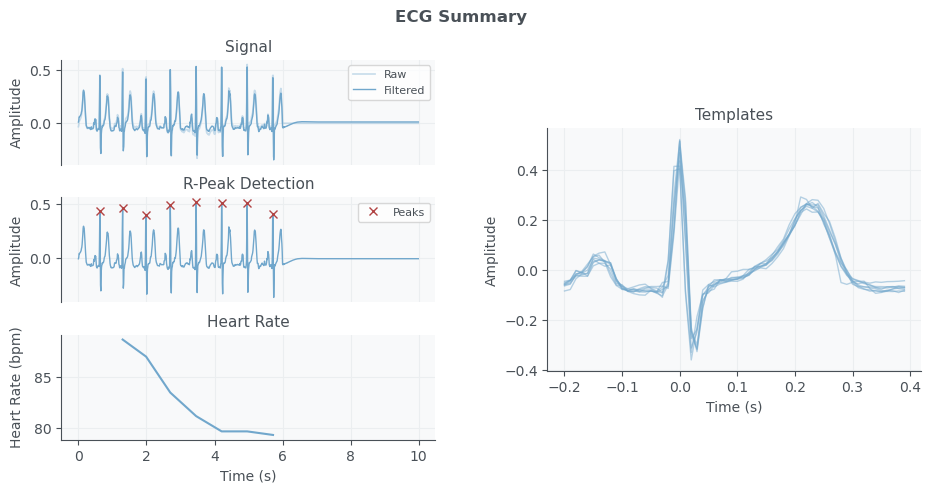

array([ 63, 130, 199, 270, 346, 421, 496, 572])

In [122]:
#
# Cell 11: process it and plot
#

out = ecg.ecg(signal=signal, sampling_rate=100., show=True)[2]
out